# 01 — Calibração do CCA pela Lei de Zipf (América do Norte até o Panamá)

Calibra os parâmetros do *City Clustering Algorithm* ($D^*$: limiar de densidade; $\ell$: distância de agregação) sobre o raster populacional GPW v4 (2020):

* **Grade de busca:** $D^* \in [10, 3000]$ hab/km² (passo 10) $\times$ $\ell \in [100, 5000]$ m (passo 100).
* **Critério de Zipf:** para cada par $(D^*, \ell)$, estima-se o expoente $\alpha$ do *rank-size* ($S(r) \propto r^{-\alpha}$) nas $N \in \{50, 100, 200\}$ maiores manchas via estimador de Hill. Seleciona-se o par com $\ell \geq \ell_{\min}$ que minimiza $\Delta(D^*, \ell) = \max_N |\alpha_N - 1|$.
* **Saída:** grava `results/cca_calibracao.json`, lido pelo `02_Micro_Plastic.ipynb`.

## 1. Setup e Recorte Continental

Recorte da América do Norte até o Canal do Panamá ($125^\circ\text{O}$ a $65^\circ\text{O}$, $7^\circ\text{N}$ a $50^\circ\text{N}$), mascarando a porção da América do Sul a leste do canal ($\text{lat} < 12{,}6^\circ\text{N}$ e $\text{lon} > -79{,}0^\circ\text{O}$).

In [1]:
import glob, json, os, subprocess, sys, time, warnings, zipfile

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rioxarray", "powerlaw"], check=True)

def local(caminho):
    for base in (".", "..", "dados", os.path.join("..", "dados")):
        p = os.path.join(base, caminho)
        if os.path.exists(p):
            return p
    return None

if local("gpw_data") is None:
    import gdown
    gdown.download(id="1c7nym3mWXzcy7iy_j1MQmCs4-RCZG0kO", output="gpw_data.zip", quiet=True)
    zipfile.ZipFile("gpw_data.zip").extractall("gpw_data")
GPW_DIR = local("gpw_data")

if not os.path.isdir("CCA"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/skaduhs5232/CCA.git", "CCA"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import rioxarray
import powerlaw
from numba import njit
from scipy import stats, ndimage as ndi
sys.path.insert(0, "CCA")
from cca import cca_grid

os.makedirs("results", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "mathtext.fontset": "dejavuserif",
    "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 8.5, "legend.fontsize": 6.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})

BOX = minx, miny, maxx, maxy = (-125.0, 7.0, -65.0, 50.0)
CANAL_LON, CANAL_LAT = -79.0, 12.6
TAG = "na_panama"

gpw = rioxarray.open_rasterio(glob.glob(os.path.join(GPW_DIR, "*.tif"))[0]).squeeze()
pop = gpw.rio.clip_box(*BOX).where(lambda x: x > 0, 0.0)
pop.rio.write_crs("EPSG:4326", inplace=True)
lon, lat = pop.x.values, pop.y.values
sul = (lat[:, None] < CANAL_LAT) & (lon[None, :] > CANAL_LON)
pop_px = np.where(sul, 0.0, np.nan_to_num(pop.values, nan=0.0)).astype(np.float64)

dx, dy = np.abs(pop.rio.resolution())
area_px_km2 = ((dx * 111.32) * np.cos(np.radians(lat)))[:, None] * (dy * 111.32)
dens_km2 = pop_px / area_px_km2
print(f"GPW: {pop_px.shape[0]} x {pop_px.shape[1]} pixels | população do recorte: {pop_px.sum():,.0f}")

GPW: 5161 x 7201 pixels | população do recorte: 606,608,535


## 2. Varredura $(D^*, \ell)$ via Union-Find Incremental

* **Algoritmo:** para cada $\ell$, os pixels são ativados em ordem decrescente de densidade e unidos (*union-find*) aos vizinhos ativos a menos de $\ell$ (distância haversine). Ao cruzar cada limiar $D^*$, registra-se a distribuição exata de populações do CCA em uma única passada.
* **Estimador de Hill:** $\alpha_N = \frac{1}{N-1} \sum_{i=1}^{N} \ln(S_i / S_N)$ para $N \in \{50, 100, 200\}$.
* **Escala mínima ($\ell_{\min}$):** exige-se $\ell$ superior à diagonal máxima do pixel (~1,3 km) para garantir conectividade em 8 vizinhos.

In [2]:
D_GRADE = np.arange(10, 3001, 10)          # hab/km²
L_GRADE = np.arange(100, 5001, 100)        # metros
R_TERRA = 6378.137                         # km
N_TOPO = (50, 100, 200)
nrows, ncols = dens_km2.shape
dens_f, pop_f = dens_km2.ravel(), pop_px.ravel()

ordem = np.flatnonzero(dens_f > D_GRADE.min())
ordem = ordem[np.argsort(-dens_f[ordem], kind="stable")].astype(np.int64)
print(f"{ordem.size:,} pixels com densidade > {D_GRADE.min()} hab/km²")

def vizinhanca(l_km):
    dlat, dlon = np.radians(dy), np.radians(dx)
    ri = int(np.ceil(l_km / (R_TERRA * dlat)))
    rj = int(np.ceil(l_km / (R_TERRA * dlon * np.cos(np.radians(np.abs(lat).max() + dy)))))
    di, dj = np.meshgrid(np.arange(-ri, ri + 1), np.arange(-rj, rj + 1), indexing="ij")
    m = (di != 0) | (dj != 0)
    di, dj = di[m], dj[m]
    lat0 = np.radians(lat)[:, None]
    lat1 = lat0 + di[None, :] * np.radians(lat[1] - lat[0])
    h = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dj[None, :] * dlon / 2) ** 2
    valido = 2 * R_TERRA * np.arcsin(np.sqrt(np.clip(h, 0, 1))) < l_km
    u = valido.any(axis=0)
    return di[u].astype(np.int64), dj[u].astype(np.int64), np.ascontiguousarray(valido[:, u])

@njit
def _raiz(pai, p):
    r = p
    while pai[r] != r:
        r = pai[r]
    while pai[p] != r:
        q = pai[p]
        pai[p] = r
        p = q
    return r

@njit
def ativa_ate(D, pos, ordem, dens, popv, pai, tam, soma, ativo, di, dj, valido, nrows, ncols):
    while pos < ordem.size:
        p = ordem[pos]
        if dens[p] <= D:
            break
        ativo[p], pai[p], tam[p], soma[p] = True, p, 1, popv[p]
        r = p // ncols
        c = p - r * ncols
        for k in range(di.size):
            if valido[r, k]:
                rr, cc = r + di[k], c + dj[k]
                if 0 <= rr < nrows and 0 <= cc < ncols:
                    q = rr * ncols + cc
                    if ativo[q]:
                        a, b = _raiz(pai, p), _raiz(pai, q)
                        if a != b:
                            if tam[a] < tam[b]:
                                a, b = b, a
                            pai[b] = a
                            tam[a] += tam[b]
                            soma[a] += soma[b]
        pos += 1
    return pos

@njit
def pops_manchas(ordem, pos, pai, soma):
    out = np.empty(pos)
    m = 0
    for i in range(pos):
        p = ordem[i]
        if pai[p] == p:
            out[m] = soma[p]
            m += 1
    return out[:m]

def alpha_hill(x, n):
    if x.size < n:
        return np.nan
    s = np.partition(x, x.size - n)[-n:]
    return float(np.sum(np.log(s / s.min())) / (n - 1))

i_eq = int(np.abs(lat).argmin())
lat0, lat1 = np.radians(lat[i_eq]), np.radians(lat[i_eq] + dy)
diag_km = 2 * R_TERRA * np.arcsin(np.sqrt(np.sin((lat1 - lat0) / 2) ** 2
                                          + np.cos(lat0) * np.cos(lat1) * np.sin(np.radians(dx) / 2) ** 2))
L_MIN = int(np.ceil(diag_km * 10) * 100)
print(f"diagonal entre pixels vizinhos: até {diag_km * 1000:.0f} m -> escolha só com l >= {L_MIN} m")

4,095,500 pixels com densidade > 10 hab/km²
diagonal entre pixels vizinhos: até 1307 m -> escolha só com l >= 1400 m


In [3]:
forma = (len(L_GRADE), len(D_GRADE))
M = {c: np.full(forma, np.nan) for c in [f"alpha{n}" for n in N_TOPO] + ["n_manchas", "maior"]}
pai = np.zeros(dens_f.size, dtype=np.int64)
tam = np.zeros(dens_f.size, dtype=np.int64)
soma = np.zeros(dens_f.size)
ativo = np.zeros(dens_f.size, dtype=np.bool_)

t0, chave_ant = time.time(), None
for i, l_m in enumerate(L_GRADE):
    di, dj, valido = vizinhanca(l_m / 1000)
    chave = (di.tobytes(), dj.tobytes(), valido.tobytes())
    if chave == chave_ant:
        for c in M:
            M[c][i] = M[c][i - 1]
        continue
    chave_ant = chave
    ativo[ordem] = False
    pos = 0
    for j in range(len(D_GRADE) - 1, -1, -1):
        pos = ativa_ate(float(D_GRADE[j]), pos, ordem, dens_f, pop_f, pai, tam, soma, ativo, di, dj, valido, nrows, ncols)
        x = pops_manchas(ordem, pos, pai, soma)
        for n in N_TOPO:
            M[f"alpha{n}"][i, j] = alpha_hill(x, n)
        M["n_manchas"][i, j] = x.size
        M["maior"][i, j] = x.max() if x.size else np.nan
    if l_m % 500 == 0 or l_m in (100, L_MIN, 1700):
        print(f"l = {l_m:>4} m | {di.size:>3} vizinhos | alpha(N=100) de {np.nanmin(M['alpha100'][i]):.2f} a "
              f"{np.nanmax(M['alpha100'][i]):.2f} | {time.time() - t0:,.0f} s")

np.savez_compressed(f"results/zipf_matriz_{TAG}.npz", D_star=D_GRADE, l_metros=L_GRADE, L_MIN=L_MIN, **M)

l =  100 m |   0 vizinhos | alpha(N=100) de 0.45 a 0.45 | 3 s
l = 1000 m |   4 vizinhos | alpha(N=100) de 0.86 a 1.42 | 12 s
l = 1400 m |  10 vizinhos | alpha(N=100) de 0.84 a 1.42 | 16 s
l = 1500 m |  10 vizinhos | alpha(N=100) de 0.85 a 1.47 | 18 s
l = 1700 m |  14 vizinhos | alpha(N=100) de 0.86 a 1.51 | 21 s
l = 2000 m |  22 vizinhos | alpha(N=100) de 0.89 a 1.55 | 27 s
l = 2500 m |  32 vizinhos | alpha(N=100) de 0.90 a 1.58 | 40 s
l = 3000 m |  48 vizinhos | alpha(N=100) de 0.89 a 1.62 | 68 s
l = 3500 m |  64 vizinhos | alpha(N=100) de 0.86 a 1.63 | 96 s
l = 4000 m |  88 vizinhos | alpha(N=100) de 0.92 a 1.74 | 117 s
l = 4500 m | 110 vizinhos | alpha(N=100) de 0.91 a 1.68 | 141 s
l = 5000 m | 142 vizinhos | alpha(N=100) de 0.91 a 1.71 | 170 s


## 3. Matriz $D^* \times \ell$ e Seleção de Parâmetros

Na lei de Zipf pura ($S(r) \propto r^{-1}$), $\alpha_N = 1$ independe do corte $N$. Seleciona-se $(D^*, \ell)$ com $\ell \geq \ell_{\min}$ que minimiza o desvio máximo entre as escalas:

$$\Delta(D^*, \ell) = \max_{N \in \{50, 100, 200\}} |\alpha_N - 1|$$

Escolha: D* = 1010 hab/km², l = 1700 m | alpha(N=50) = 0.925, alpha(N=100) = 0.939, alpha(N=200) = 1.081 | Delta = 0.081 | 12185 manchas


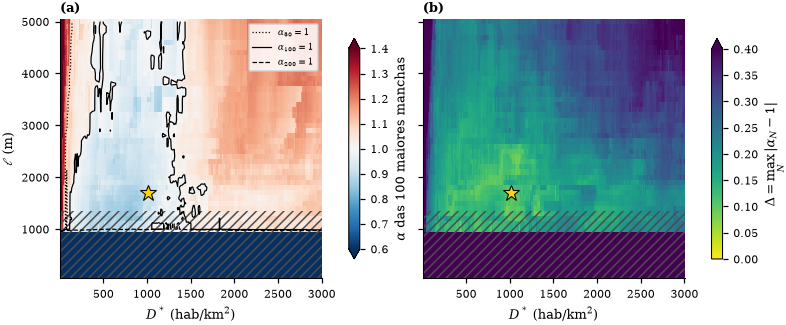

 l_m  D_star  delta  alpha50  alpha100  alpha200
1400     960  0.081    0.919     0.926     1.053
1500     970  0.088    0.917     0.912     1.079
1600    1040  0.098    0.903     0.917     1.098
1700    1010  0.081    0.925     0.939     1.081
1800     630  0.090    0.910     0.915     1.088
1900     820  0.091    0.959     0.909     1.089
2000     850  0.097    0.942     0.903     1.096
2100    1110  0.090    0.936     0.945     1.090
2200    1100  0.093    0.963     0.950     1.093
2300    1110  0.083    0.965     0.942     1.083
2400    1110  0.085    0.952     0.947     1.085
2500    1110  0.100    0.962     0.959     1.100
2600    1110  0.108    0.961     0.965     1.108
2700     420  0.131    0.880     0.912     1.131
2800     460  0.133    0.950     0.969     1.133
2900     460  0.135    0.865     1.008     1.133
3000     460  0.136    0.867     0.983     1.136
3100     460  0.144    0.870     0.985     1.144
3200     590  0.145    0.944     0.990     1.145
3300     670  0.146 

In [4]:
A = np.stack([M[f"alpha{n}"] for n in N_TOPO])
desvio = np.max(np.abs(A - 1), axis=0)
permitido = (L_GRADE >= L_MIN)[:, None] & np.isfinite(desvio)
i_esc, j_esc = np.unravel_index(np.nanargmin(np.where(permitido, desvio, np.nan)), desvio.shape)
D_esc, l_esc = int(D_GRADE[j_esc]), int(L_GRADE[i_esc])
alphas_esc = {n: float(M[f"alpha{n}"][i_esc, j_esc]) for n in N_TOPO}
criterio = f"min max_N |alpha_N - 1|, N em {N_TOPO}, l >= {L_MIN} m"
print(f"Escolha: D* = {D_esc} hab/km², l = {l_esc} m | "
      + ", ".join(f"alpha(N={n}) = {a:.3f}" for n, a in alphas_esc.items())
      + f" | Delta = {desvio[i_esc, j_esc]:.3f} | {int(M['n_manchas'][i_esc, j_esc])} manchas")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True, sharey=True)
extent = (D_GRADE[0] - 5, D_GRADE[-1] + 5, L_GRADE[0] - 50, L_GRADE[-1] + 50)
im0 = axes[0].imshow(M["alpha100"], origin="lower", aspect="auto", extent=extent, cmap="RdBu_r",
                     norm=TwoSlopeNorm(vmin=0.6, vcenter=1.0, vmax=1.4), interpolation="nearest")
for n, ls in zip(N_TOPO, (":", "-", "--")):
    axes[0].contour(D_GRADE, L_GRADE, M[f"alpha{n}"], levels=[1.0], colors="k", linewidths=0.8, linestyles=ls)
fig.colorbar(im0, ax=axes[0], shrink=0.85, label=r"$\alpha$ das 100 maiores manchas", extend="both")

im1 = axes[1].imshow(desvio, origin="lower", aspect="auto", extent=extent, cmap="viridis_r",
                     vmin=0, vmax=0.4, interpolation="nearest")
fig.colorbar(im1, ax=axes[1], shrink=0.85, label=r"$\Delta = \max_N |\alpha_N - 1|$", extend="max")

for ax, l in zip(axes, "ab"):
    ax.axhspan(extent[2], L_MIN - 50, facecolor="none", edgecolor="0.3", hatch="////", lw=0)
    ax.plot(D_esc, l_esc, marker="*", ms=11, mfc="gold", mec="k", mew=0.7, ls="")
    ax.set_xlabel(r"$D^*$ (hab/km$^2$)")
    ax.text(0.0, 1.015, f"({l})", transform=ax.transAxes, fontweight="bold", va="bottom")
axes[0].legend(handles=[plt.Line2D([], [], c="k", lw=0.8, ls=ls, label=rf"$\alpha_{{{n}}} = 1$")
                        for n, ls in zip(N_TOPO, (":", "-", "--"))], loc="upper right", fontsize=6,
               frameon=True, framealpha=0.85)
axes[0].set_ylabel(r"$\ell$ (m)")
fig.savefig(f"results/zipf_matriz_{TAG}.pdf")
fig.savefig(f"results/zipf_matriz_{TAG}.png")
plt.show()

curva = pd.DataFrame([
    {"l_m": int(l), "D_star": int(D_GRADE[j]), "delta": desvio[i, j], **{f"alpha{n}": M[f"alpha{n}"][i, j] for n in N_TOPO}}
    for i, l in enumerate(L_GRADE) if l >= L_MIN and np.isfinite(desvio[i]).any()
    for j in [int(np.nanargmin(desvio[i]))]
])
curva.to_csv(f"results/zipf_curva_alpha1_{TAG}.csv", index=False)
print(curva.round(3).to_string(index=False))

## 4. Validação no `cca_grid` e Ajuste de Clauset–Shalizi–Newman (2009)

Executa o `cca_grid` no par ótimo $(D^*, \ell)$ e aplica o teste de Clauset–Shalizi–Newman (2009) à distribuição de populações $p(x) \propto x^{-\gamma}$ ($\alpha = 1/(\gamma - 1)$):

1. $x_{\min}$ selecionado minimizando a estatística de Kolmogorov–Smirnov (KS) na cauda $x \geq x_{\min}$;
2. Bondade de ajuste via *bootstrap* semiparamétrico ($p > 0{,}10$ indica compatibilidade com lei de potência);
3. Razão de verossimilhança ($R$) contra distribuições lognormal, exponencial e *power-law* truncada.

In [5]:
cidades, pop_cid, area_cid = cca_grid(pop_px, lon, lat, area_px_km2, D_esc, l_esc / 1000)
n_cca = len(pop_cid)
print(f"cca_grid: {n_cca} manchas, maior {pop_cid.max():,.0f} hab | varredura: "
      f"{int(M['n_manchas'][i_esc, j_esc])} manchas, maior {M['maior'][i_esc, j_esc]:,.0f} hab")
print("alpha de Hill no cca_grid: " + ", ".join(f"N={n}: {alpha_hill(pop_cid, n):.3f}" for n in N_TOPO))

borda = np.zeros(n_cca + 1, dtype=bool)
for faixa in (cidades[0, :], cidades[-1, :], cidades[:, 0], cidades[:, -1]):
    borda[np.unique(faixa)] = True
centro = np.array(ndi.center_of_mass(pop_px, cidades, index=np.arange(1, n_cca + 1)))

REFS_CIDADES = {
    "Cidade do México": (-99.13, 19.43), "Nova York": (-74.00, 40.71), "Los Angeles": (-118.24, 34.05),
    "Chicago": (-87.63, 41.88), "Houston": (-95.37, 29.76), "Miami": (-80.19, 25.76),
    "Filadélfia": (-75.16, 39.95), "Washington": (-77.04, 38.91), "Boston": (-71.06, 42.36),
    "São Francisco": (-122.42, 37.77), "Seattle": (-122.33, 47.61), "Toronto": (-79.38, 43.65),
    "Montreal": (-73.57, 45.50), "Guadalajara": (-103.35, 20.67), "Monterrey": (-100.31, 25.69),
    "Dallas": (-96.80, 32.78), "Atlanta": (-84.39, 33.75), "Phoenix": (-112.07, 33.45),
    "Detroit": (-83.05, 42.33), "Puebla": (-98.20, 19.04), "San Diego/Tijuana": (-117.04, 32.62),
    "Nova Orleans": (-90.07, 29.95), "Tampa": (-82.46, 27.95), "Havana": (-82.37, 23.11),
    "Santo Domingo": (-69.93, 18.49), "Porto Príncipe": (-72.33, 18.54),
    "Cidade da Guatemala": (-90.51, 14.63), "San Salvador": (-89.19, 13.69),
    "Cidade do Panamá": (-79.52, 8.98), "Corpus Christi": (-97.40, 27.80), "Veracruz": (-96.13, 19.18),
}

def nomeia(cidades, pesos, lon, lat, refs, janela=3):
    nomes = {}
    for nome, (lo, la) in refs.items():
        r, c = int(np.abs(lat - la).argmin()), int(np.abs(lon - lo).argmin())
        w = cidades[max(r - janela, 0):r + janela + 1, max(c - janela, 0):c + janela + 1]
        p = pesos[max(r - janela, 0):r + janela + 1, max(c - janela, 0):c + janela + 1]
        if (w > 0).any():
            ids_w, inv = np.unique(w[w > 0], return_inverse=True)
            nomes.setdefault(int(ids_w[np.bincount(inv, weights=p[w > 0]).argmax()]), nome)
    return nomes

df = pd.DataFrame({
    "cluster": np.arange(1, n_cca + 1), "pop": pop_cid, "area_km2": area_cid, "borda": borda[1:],
    "lon": np.interp(centro[:, 1], np.arange(lon.size), lon),
    "lat": np.interp(centro[:, 0], np.arange(lat.size), lat),
    "nome": pd.Series(np.arange(1, n_cca + 1)).map(nomeia(cidades, pop_px, lon, lat, REFS_CIDADES)),
}).query("pop > 0").reset_index(drop=True)
df.to_csv(f"results/zipf_clusters_{TAG}.csv", index=False)

cca_grid: 12185 manchas, maior 20,602,596 hab | varredura: 12185 manchas, maior 20,602,596 hab
alpha de Hill no cca_grid: N=50: 0.925, N=100: 0.939, N=200: 1.081


In [6]:
def _melhor_xmin(x, min_cauda=30):
    xs = np.sort(np.asarray(x, dtype=float))
    n, lx = len(xs), np.log(xs)
    soma_cauda = np.cumsum(lx[::-1])[::-1]
    _, inicio = np.unique(xs, return_index=True)
    melhor = None
    for k in inicio[:-min_cauda]:
        nt = n - k
        gamma = 1.0 + nt / (soma_cauda[k] - nt * lx[k])
        if gamma <= 1.05:
            continue
        ks = float(np.max(np.abs(np.arange(1, nt + 1) / nt - (1.0 - (xs[k:] / xs[k]) ** (1.0 - gamma)))))
        if melhor is None or ks < melhor["ks"]:
            melhor = dict(xmin=float(xs[k]), n=int(nt), gamma=float(gamma), ks=ks)
    return melhor

def ajusta_zipf(pop, n_boot=200, semente=42):
    pop = np.asarray(pop[pop > 0], dtype=float)
    m = _melhor_xmin(pop)
    gamma, nx, xmin = m["gamma"], m["n"], m["xmin"]
    m["erro_gamma"] = (gamma - 1.0) / np.sqrt(nx)
    m["alpha"] = 1.0 / (gamma - 1.0)
    m["erro_alpha"] = m["erro_gamma"] / (gamma - 1.0) ** 2
    m["ks_critico"] = 1.36 / np.sqrt(nx)

    rng, corpo, n = np.random.default_rng(semente), pop[pop < xmin], len(pop)
    piores = validos = 0
    for _ in range(n_boot):
        k = rng.binomial(n, nx / n)
        cauda = xmin * (1.0 - rng.random(k)) ** (-1.0 / (gamma - 1.0))
        rs = _melhor_xmin(np.concatenate([cauda, rng.choice(corpo, n - k)]) if len(corpo) else cauda)
        if rs is not None:
            validos += 1
            piores += rs["ks"] >= m["ks"]
    m["p_valor"] = (piores / validos) if validos else float("nan")

    xc = np.sort(pop[pop >= xmin])[::-1]
    rr = np.arange(1, len(xc) + 1)
    m["alpha_ols"] = float(-np.polyfit(np.log10(rr), np.log10(xc), 1)[0])
    m["r2_ols"] = float(stats.pearsonr(np.log10(rr), np.log10(xc))[0] ** 2)
    return m

fit = ajusta_zipf(df["pop"].to_numpy())
print(f"{len(df)} manchas | {int(df['borda'].sum())} tocam a borda | população urbana "
      f"{df['pop'].sum():,.0f} ({df['pop'].sum() / pop_px.sum():.0%} do recorte)")
print(f"xmin={fit['xmin']:,.0f} (n={fit['n']})  gamma={fit['gamma']:.3f}±{fit['erro_gamma']:.3f}"
      f"  alpha={fit['alpha']:.3f}±{fit['erro_alpha']:.3f}")
print(f"KS={fit['ks']:.4f} (crítico {fit['ks_critico']:.4f})  p={fit['p_valor']:.2f}"
      f"  | alpha_OLS={fit['alpha_ols']:.3f} (R²={fit['r2_ols']:.3f})")

with warnings.catch_warnings(), np.errstate(all="ignore"):
    warnings.simplefilter("ignore")
    f = powerlaw.Fit(df["pop"].to_numpy(), xmin=fit["xmin"], verbose=False)
    for alt in ("lognormal", "exponential", "truncated_power_law"):
        R, p = f.distribution_compare("power_law", alt, normalized_ratio=True)
        fit[f"R_{alt}"], fit[f"p_{alt}"] = float(R), float(p)
        print(f"power law vs {alt}: R = {R:.3f}, p = {p:.3f}")

12185 manchas | 2 tocam a borda | população urbana 349,521,349 (58% do recorte)
xmin=21,121 (n=1325)  gamma=1.822±0.023  alpha=1.217±0.033
KS=0.0172 (crítico 0.0374)  p=0.08  | alpha_OLS=1.163 (R²=0.994)
power law vs lognormal: R = -1.287, p = 0.198
power law vs exponential: R = 8.640, p = 0.000
power law vs truncated_power_law: R = -2.516, p = 0.004


## 5. As 10 Maiores Aglomerações Urbanas e Curva *Rank-Size*

Verificação geográfica dos maiores aglomerados identificados pelo CCA e ajuste *rank-size* ($S(r) \propto r^{-\alpha}$). *(Nota: a alta densidade média de Monterrey reflete uma anomalia conhecida do GPW v4 a ~25,9°N, 100,17°O, onde o CCA agrega os pixels ao cluster principal sem distorcer a população total da metrópole).*

 cluster             nome        pop  area_km2  dens_hab_km2     lon   lat  borda
   10503 Cidade do México 20,602,596     2,204         9,349  -99.10 19.45  False
    2985        Nova York 15,482,384     3,316         4,669  -73.92 40.75  False
    6749      Los Angeles 14,240,127     4,017         3,545 -118.03 33.98  False
    2175          Chicago  6,335,092     2,253         2,812  -87.83 41.85  False
    1217          Toronto  6,029,628     1,372         4,394  -79.49 43.71  False
    9131            Miami  5,329,254     2,073         2,570  -80.24 26.05  False
    9919      Guadalajara  5,073,091       594         8,547 -103.35 20.63  False
    9306        Monterrey  4,971,276       637         7,800 -100.28 25.72  False
    8428          Houston  4,814,175     1,982         2,429  -95.46 29.76  False
   11135    Santo Domingo  4,737,554       947         5,004  -69.92 18.50  False


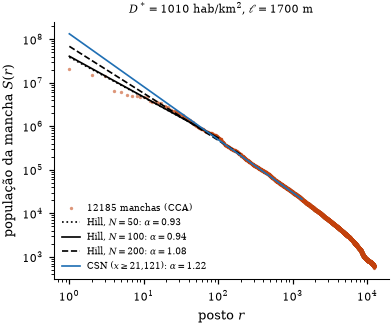

In [7]:
top = df.sort_values("pop", ascending=False).head(10).assign(dens_hab_km2=lambda d: d["pop"] / d["area_km2"])
print(top[["cluster", "nome", "pop", "area_km2", "dens_hab_km2", "lon", "lat", "borda"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.2f}" if abs(v) < 400 else f"{v:,.0f}"))

x = np.sort(df["pop"].to_numpy())[::-1]
r, nt = np.arange(1, len(x) + 1), fit["n"]
fig, ax = plt.subplots(figsize=(3.6, 3.0), constrained_layout=True)
ax.loglog(r, x, "o", ms=2.2, mfc="#c2410c", mec="none", alpha=0.55, label=f"{len(x)} manchas (CCA)")
for n, ls in zip(N_TOPO, (":", "-", "--")):
    a = alphas_esc[n]
    rr = np.logspace(0, np.log10(n), 30)
    ax.loglog(rr, x[n - 1] * (rr / n) ** (-a), ls=ls, c="k", lw=1.1, label=rf"Hill, $N={n}$: $\alpha={a:.2f}$")
rr = np.logspace(0, np.log10(nt), 60)
ax.loglog(rr, fit["xmin"] * (rr / nt) ** (-fit["alpha"]), "-", c="#1f6fb4", lw=1.1,
          label=r"CSN ($x\geq$" + f"{fit['xmin']:,.0f}): " + rf"$\alpha={fit['alpha']:.2f}$")
ax.set(xlabel=r"posto $r$", ylabel=r"população da mancha $S(r)$")
ax.set_title(rf"$D^*={D_esc}$ hab/km$^2$, $\ell={l_esc}$ m", fontsize=7.5)
ax.legend(fontsize=5.8, loc="lower left")
fig.savefig(f"results/zipf_{TAG}.pdf")
fig.savefig(f"results/zipf_{TAG}.png")
plt.show()

## 6. Exportação dos Parâmetros Calibrados

In [8]:
calibracao = {
    "D_star": D_esc, "l_metros": l_esc,
    "alpha_hill": {str(n): a for n, a in alphas_esc.items()},
    "delta": float(desvio[i_esc, j_esc]), "l_min_m": L_MIN, "criterio": criterio,
    "grade": {"D_star": [int(D_GRADE[0]), int(D_GRADE[-1]), 10], "l_metros": [int(L_GRADE[0]), int(L_GRADE[-1]), 100]},
    "box": list(BOX), "canal": {"lon": CANAL_LON, "lat": CANAL_LAT},
    "ajuste_csn": {k: float(v) for k, v in fit.items()},
}
with open("results/cca_calibracao.json", "w", encoding="utf-8") as f:
    json.dump(calibracao, f, indent=2, ensure_ascii=False)
print(json.dumps(calibracao, indent=2, ensure_ascii=False))

{
  "D_star": 1010,
  "l_metros": 1700,
  "alpha_hill": {
    "50": 0.9252499576026287,
    "100": 0.9390162084585852,
    "200": 1.0806087970118199
  },
  "delta": 0.08060879701181989,
  "l_min_m": 1400,
  "criterio": "min max_N |alpha_N - 1|, N em (50, 100, 200), l >= 1400 m",
  "grade": {
    "D_star": [
      10,
      3000,
      10
    ],
    "l_metros": [
      100,
      5000,
      100
    ]
  },
  "box": [
    -125.0,
    7.0,
    -65.0,
    50.0
  ],
  "canal": {
    "lon": -79.0,
    "lat": 12.6
  },
  "ajuste_csn": {
    "xmin": 21121.206970214844,
    "n": 1325.0,
    "gamma": 1.8215662309751066,
    "ks": 0.017202230217416098,
    "erro_gamma": 0.02257016016158791,
    "alpha": 1.2171873213594875,
    "erro_alpha": 0.03343870737862667,
    "ks_critico": 0.03736207339404342,
    "p_valor": 0.08,
    "alpha_ols": 1.163242796465795,
    "r2_ols": 0.9936081952424949,
    "R_lognormal": -1.2866639412355185,
    "p_lognormal": 0.19821144648814704,
    "R_exponential": 8.640322